# 03. Выбор модели: три алгоритма, подбор гиперпараметров, проверка гипотез H1 и H2

**Блок 3.2.** Кандидаты (помимо baseline — логистической регрессии):
- **Random Forest** — ансамбль независимых деревьев;
- **градиентный бустинг** (`HistGradientBoostingClassifier`) — деревья, обучаемые последовательно на ошибках предыдущих;
- **нейронная сеть** (`MLPClassifier`) — алгоритм на выбор, принципиально отличный от деревьев.

Протокол:
1. **Подбор гиперпараметров** — случайный поиск (`RandomizedSearchCV`), кросс-валидация GroupKFold на 5 блоков
   по двигателям, метрика PR-AUC.
2. **Оценка** лучшей конфигурации каждого алгоритма — те же 10 блоков по двигателям, что у baseline,
   поэтому оценки парные и их можно сравнивать статистически.
3. **Порог** — наибольший, при котором нижняя граница 95% доверительного интервала Recall (бутстрап по
   двигателям, 1000 повторов) ≥ 0,85. Правило выбрано до просмотра тестовой выборки.
4. **Тестовая выборка не используется**: модель выбирается только по кросс-валидации на train.

Расчёт выполняет `python -m src.models.train_candidates` (≈ 30 минут); ноутбук читает его результаты
из `models/selection/`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon
from sklearn.metrics import average_precision_score, precision_recall_curve

from src.models.metrics import MIN_RECALL

FIG_DIR = ROOT / "docs" / "figures"
SEL = ROOT / "models" / "selection"
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4, "display.max_colwidth", 120)

sel = json.loads((SEL / "model_selection.json").read_text(encoding="utf-8"))
oof = pd.read_csv(SEL / "oof_predictions.csv")
NAMES = {"logistic_regression": "Логистическая регрессия (baseline)", "random_forest": "Random Forest",
         "hist_gradient_boosting": "Градиентный бустинг", "mlp": "Нейросеть (MLP)"}
models = sel["models"]
print("Тестовая выборка использовалась:", sel["protocol"]["test_used"])

Тестовая выборка использовалась: False


## 1. Подбор гиперпараметров

In [2]:
rows = []
for k, m in models.items():
    t = m["tuning"]
    if t is None:
        rows.append({"модель": NAMES[k], "конфигураций": "— (без подбора)", "PR-AUC (5 блоков)": np.nan,
                     "время подбора, с": np.nan, "лучшие параметры": "C=1, class_weight=balanced"})
    else:
        rows.append({"модель": NAMES[k], "конфигураций": t["n_configs"], "PR-AUC (5 блоков)": t["tuning_pr_auc"],
                     "время подбора, с": t["tuning_seconds"], "лучшие параметры": t["best_params"]})
pd.DataFrame(rows).set_index("модель")

,конфигураций,PR-AUC (5 блоков),"время подбора, с",лучшие параметры
модель,,,,
Логистическая регрессия (baseline),— (без подбора),NaN,NaN,"C=1, class_weight=balanced"
Random Forest,12,0.9828,647.1,"{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 16, 'class_weight': None}"
Градиентный бустинг,20,0.9903,767.0,"{'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 0.0, 'c..."
Нейросеть (MLP),10,0.9920,97.9,"{'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': [32], 'clf__batch_size': 128, 'clf__alpha': 0.0001}"


In [3]:
for k, m in models.items():
    if m["tuning"]:
        print(f"\n{NAMES[k]}: 5 лучших конфигураций")
        display(pd.DataFrame(m["tuning"]["top5"]))


Random Forest: 5 лучших конфигураций


,params,pr_auc_mean,pr_auc_std,fit_seconds
0,"{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 16, 'class_weight': None}",0.9828,0.0052,12.58
1,"{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': None, 'class_weight': None}",0.9827,0.0052,11.72
2,"{'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': None}",0.9815,0.0049,9.69
3,"{'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': None}",0.9811,0.0048,5.31
4,"{'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': 'balanced_subs...",0.9788,0.0058,4.83



Градиентный бустинг: 5 лучших конфигураций


,params,pr_auc_mean,pr_auc_std,fit_seconds
0,"{'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 0.0, 'c...",0.9903,0.0049,14.30
1,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.1, 'l2_regularization': 0.0, 'cla...",0.9902,0.0043,3.06
2,"{'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.0, 'cl...",0.9901,0.0052,1.76
3,"{'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.1, 'l2_regularization': 0.1, 'cla...",0.9901,0.0047,2.85
4,"{'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 1.0, 'cl...",0.9900,0.0047,10.67



Нейросеть (MLP): 5 лучших конфигураций


,params,pr_auc_mean,pr_auc_std,fit_seconds
0,"{'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': [32], 'clf__batch_size': 128, 'clf__alpha': 0.0001}",0.9920,0.0014,5.43
1,"{'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': [64], 'clf__batch_size': 256, 'clf__alpha': 0.1}",0.9919,0.0006,7.32
2,"{'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': [64, 32], 'clf__batch_size': 128, 'clf__alpha': 0.1}",0.9919,0.0005,9.64
3,"{'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': [32], 'clf__batch_size': 128, 'clf__alpha': 0.001}",0.9918,0.0015,7.56
4,"{'clf__learning_rate_init': 0.003, 'clf__hidden_layer_sizes': [32], 'clf__batch_size': 256, 'clf__alpha': 0.001}",0.9915,0.0017,4.96


## 2. Сравнение на 10 блоках (общий протокол)

In [4]:
rows = []
for k, m in models.items():
    p, e, thr = m["pooled_oof"], m["engine_level"], m["threshold"]
    rows.append({"модель": NAMES[k],
                 "PR-AUC среднее": m["pr_auc_mean"], "PR-AUC ст.откл.": m["pr_auc_std"],
                 "порог": thr["threshold"], "Recall": p["recall"],
                 "Recall: нижн. граница 95% ДИ": thr["recall_ci_lower"],
                 "FPR": p["fpr"], "Precision": p["precision"], "F2": p["f2"],
                 "двигателей с тревогой": e["detected_share"], "медиана запаса, циклов": e["median_lead"],
                 "p95 задержки, мс": m["latency_single_row"]["p95_ms"]})
comparison = pd.DataFrame(rows).set_index("модель").sort_values("PR-AUC среднее", ascending=False)
comparison

,PR-AUC среднее,PR-AUC ст.откл.,порог,Recall,Recall: нижн. граница 95% ДИ,FPR,Precision,F2,двигателей с тревогой,"медиана запаса, циклов","p95 задержки, мс"
модель,,,,,,,,,,,
Логистическая регрессия (baseline),0.9932,0.0031,0.9721,0.8742,0.8500,0.0019,0.9876,0.8947,1.0,27.0,5.7527
Нейросеть (MLP),0.9914,0.0021,0.8792,0.8732,0.8503,0.0024,0.9847,0.8935,1.0,28.0,1.6733
Градиентный бустинг,0.9907,0.0056,0.9578,0.8687,0.8503,0.0026,0.9832,0.8894,1.0,27.0,7.5212
Random Forest,0.9840,0.0078,0.6658,0.8719,0.8503,0.0058,0.9640,0.8889,1.0,26.0,41.0459


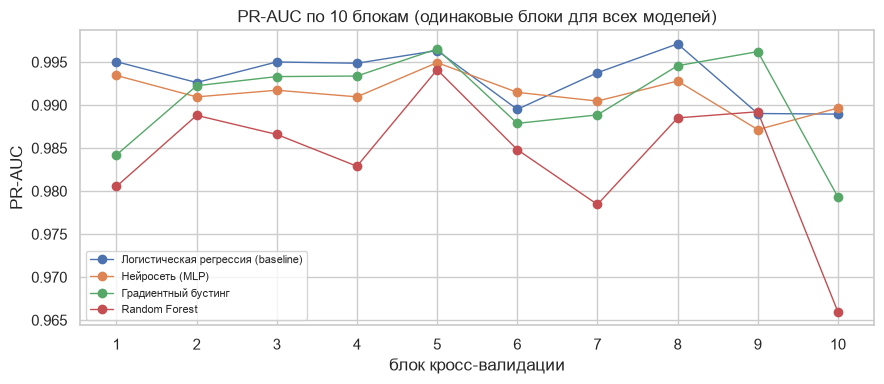

,Логистическая регрессия (baseline),Random Forest,Градиентный бустинг,Нейросеть (MLP)
1,0.9950,0.9805,0.9842,0.9934
2,0.9926,0.9888,0.9923,0.9910
3,0.9950,0.9866,0.9933,0.9917
4,0.9949,0.9829,0.9934,0.9910
5,0.9963,0.9941,0.9965,0.9949
6,0.9895,0.9848,0.9879,0.9915
7,0.9938,0.9784,0.9889,0.9905
8,0.9971,0.9885,0.9946,0.9928
9,0.9890,0.9892,0.9962,0.9871
10,0.9890,0.9660,0.9793,0.9897


In [5]:
folds = pd.DataFrame({NAMES[k]: m["fold_pr_auc"] for k, m in models.items()})
folds.index = folds.index + 1
order = comparison.index.tolist()
fig, ax = plt.subplots(figsize=(9, 4))
for i, name in enumerate(order):
    ax.plot(folds.index, folds[name], marker="o", lw=1, label=name)
ax.set(xlabel="блок кросс-валидации", ylabel="PR-AUC", title="PR-AUC по 10 блокам (одинаковые блоки для всех моделей)")
ax.set_xticks(folds.index)
ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIG_DIR / "03_folds_pr_auc.png", dpi=120); plt.show()
folds

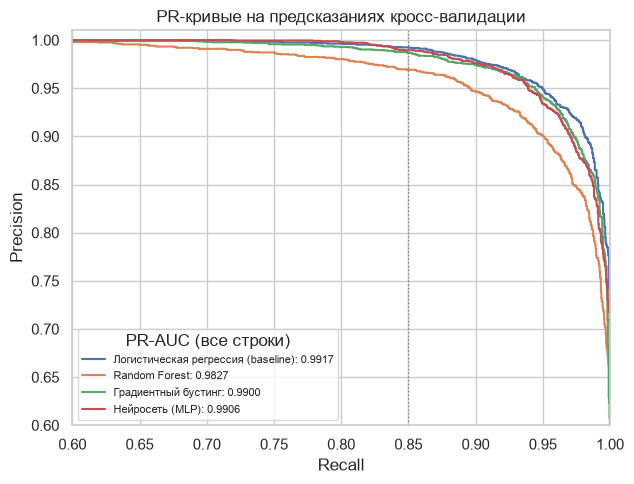

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for k in models:
    pr, rc, _ = precision_recall_curve(oof["target"], oof[k])
    ax.plot(rc, pr, label=f"{NAMES[k]}: {average_precision_score(oof['target'], oof[k]):.4f}")
ax.axvline(MIN_RECALL, color="grey", ls=":", lw=1)
ax.set(xlabel="Recall", ylabel="Precision", title="PR-кривые на предсказаниях кросс-валидации", xlim=(0.6, 1.0), ylim=(0.6, 1.01))
ax.legend(fontsize=8, loc="lower left", title="PR-AUC (все строки)")
plt.tight_layout(); fig.savefig(FIG_DIR / "03_pr_curves.png", dpi=120); plt.show()

### Recall в трудном диапазоне

В блоке 3.1 выяснилось, что слабое место — строки с RUL 21–30 (на test их доля вдвое выше). Сравним модели по этому диапазону при их порогах.

In [7]:
rows = []
pos = oof[oof["target"] == 1]
bins = pd.cut(pos["rul"], [-1, 10, 20, 30], labels=["0–10", "11–20", "21–30"])
for k, m in models.items():
    pred = pos[k] >= m["threshold"]["threshold"]
    rows.append(pred.groupby(bins, observed=True).mean().rename(NAMES[k]))
by_rul = pd.DataFrame(rows)
by_rul.columns = [f"Recall, RUL {c}" for c in by_rul.columns]
by_rul.loc[order]

,"Recall, RUL 0–10","Recall, RUL 11–20","Recall, RUL 21–30"
Логистическая регрессия (baseline),1.0,0.985,0.625
Нейросеть (MLP),1.0,0.983,0.623
Градиентный бустинг,1.0,0.991,0.602
Random Forest,1.0,0.986,0.616


## 3. Проверка гипотез H1 и H2

Односторонний критерий Уилкоксона для парных оценок PR-AUC на 10 одинаковых блоках, α = 0,05.
Критерий подтверждения (из блока 1.3): p < 0,05 и прирост > 0.

In [8]:
def wilcoxon_row(name, a, b):
    a, b = np.asarray(a), np.asarray(b)
    stat, p = wilcoxon(a, b, alternative="greater")
    gain = float(np.mean(a - b))
    return {"сравнение": name, "PR-AUC A": a.mean(), "PR-AUC B": b.mean(), "прирост (A − B)": gain,
            "блоков, где A > B": int((a > b).sum()), "p-value": p,
            "подтверждена": bool(p < 0.05 and gain > 0)}

h = sel["h1_raw_features"]
tests = pd.DataFrame([
    wilcoxon_row("H1: признаки по окну vs исходные показания — логистическая регрессия",
                 models["logistic_regression"]["fold_pr_auc"], h["logistic_regression"]["fold_pr_auc"]),
    wilcoxon_row("H1: признаки по окну vs исходные показания — градиентный бустинг",
                 models["hist_gradient_boosting"]["fold_pr_auc"], h["hist_gradient_boosting"]["fold_pr_auc"]),
    wilcoxon_row("H2: градиентный бустинг vs логистическая регрессия",
                 models["hist_gradient_boosting"]["fold_pr_auc"], models["logistic_regression"]["fold_pr_auc"]),
]).set_index("сравнение")
tests

,PR-AUC A,PR-AUC B,прирост (A − B),"блоков, где A > B",p-value,подтверждена
сравнение,,,,,,
H1: признаки по окну vs исходные показания — логистическая регрессия,0.9932,0.9542,0.0390,10,0.0010,True
H1: признаки по окну vs исходные показания — градиентный бустинг,0.9907,0.9540,0.0367,10,0.0010,True
H2: градиентный бустинг vs логистическая регрессия,0.9907,0.9932,-0.0026,2,0.9756,False


Дополнительно (не заявлялось заранее, поэтому носит описательный характер): каждый кандидат против baseline.

In [9]:
extra = pd.DataFrame([wilcoxon_row(f"{NAMES[k]} vs baseline", models[k]["fold_pr_auc"],
                                   models["logistic_regression"]["fold_pr_auc"])
                      for k in ["random_forest", "hist_gradient_boosting", "mlp"]]).set_index("сравнение")
extra

,PR-AUC A,PR-AUC B,прирост (A − B),"блоков, где A > B",p-value,подтверждена
сравнение,,,,,,
Random Forest vs baseline,0.9840,0.9932,-0.0092,1,0.9990,False
Градиентный бустинг vs baseline,0.9907,0.9932,-0.0026,2,0.9756,False
Нейросеть (MLP) vs baseline,0.9914,0.9932,-0.0019,2,0.9863,False


## 4. Выбор финальной модели

Правило: наибольшее среднее PR-AUC на 10 блоках (основная метрика проекта); при этом модель должна
выполнять требования на кросс-валидации (нижняя граница ДИ Recall ≥ 0,85, FPR < 0,15) и укладываться
во время ответа.

In [10]:
ok = comparison[(comparison["Recall: нижн. граница 95% ДИ"] >= MIN_RECALL) & (comparison["FPR"] < 0.15)
                & (comparison["p95 задержки, мс"] < 50)]
best = ok["PR-AUC среднее"].idxmax()
print("Финальная модель для блока 3.3:", best)
ok[["PR-AUC среднее", "PR-AUC ст.откл.", "Recall", "FPR", "F2", "p95 задержки, мс"]]

Финальная модель для блока 3.3: Логистическая регрессия (baseline)


,PR-AUC среднее,PR-AUC ст.откл.,Recall,FPR,F2,"p95 задержки, мс"
модель,,,,,,
Логистическая регрессия (baseline),0.9932,0.0031,0.8742,0.0019,0.8947,5.7527
Нейросеть (MLP),0.9914,0.0021,0.8732,0.0024,0.8935,1.6733
Градиентный бустинг,0.9907,0.0056,0.8687,0.0026,0.8894,7.5212
Random Forest,0.9840,0.0078,0.8719,0.0058,0.8889,41.0459


## 5. Выводы

- **Подбор гиперпараметров** (PR-AUC на 5 блоках): Random Forest — 0,983 (12 конфигураций, 11 мин),
  градиентный бустинг — 0,990 (20 конфигураций, 13 мин), нейросеть — 0,992 (10 конфигураций, 2 мин).
  У бустинга и нейросети лучшие конфигурации почти не отличаются от следующих (разница ≤ 0,0005) —
  качество упирается не в гиперпараметры, а в информацию в признаках.
- **Сравнение на 10 одинаковых блоках** (PR-AUC, среднее ± ст. откл.): логистическая регрессия 0,9932 ± 0,0031,
  нейросеть 0,9914 ± 0,0021, градиентный бустинг 0,9907 ± 0,0056, Random Forest 0,9840 ± 0,0078.
  **Ни один сложный алгоритм не превзошёл baseline**: логистическая регрессия лучше в 8–9 блоках из 10.
- **Порог с запасом** (нижняя граница 95% ДИ Recall ≥ 0,85) у всех моделей даёт Recall ≈ 0,87 на кросс-валидации
  вместо 0,85 при прежнем правиле; FPR остаётся 0,002–0,006 — далеко от предела 0,15. У логистической регрессии
  порог 0,972 (в v1 было 0,984).
- **Трудный диапазон RUL 21–30** остаётся слабым местом у всех моделей (Recall 0,60–0,63) — это свойство данных:
  за 21–30 циклов до отказа признаки износа ещё слабо выражены.
- **H1 подтверждена:** признаки по скользящему окну повышают PR-AUC по сравнению с исходными показаниями —
  для логистической регрессии с 0,954 до 0,993, для градиентного бустинга с 0,954 до 0,991; прирост во всех
  10 блоках, p = 0,001 в обоих случаях.
- **H2 не подтверждена:** градиентный бустинг не превосходит логистическую регрессию (PR-AUC 0,9907 против 0,9932,
  лучше лишь в 2 блоках из 10, p = 0,98). Вероятное объяснение: признаки по окну уже описывают износ почти
  линейно (средние, тренды, отклонение от нормы), и нелинейным моделям нечего добавить, а на 100 двигателях
  они сильнее рискуют подстроиться под шум.
- **Время ответа** одной строки (p95, замер во время расчёта, компьютер был нагружен): нейросеть 1,7 мс,
  логистическая регрессия 5,8 мс, бустинг 7,5 мс, Random Forest 41 мс — близко к пределу 50 мс на весь запрос.
- **Финальная модель для блока 3.3 — логистическая регрессия** (наибольшее PR-AUC, правило выбора задано до
  получения результатов). Она же самая простая и интерпретируемая. Версия v2 будет отличаться от v1 правилом
  порога (с запасом); тестовая выборка пока не использовалась.
- **Ограничение:** гиперпараметры подбирались на том же train, на котором затем сравнивались модели (без вложенной
  кросс-валидации), поэтому оценки кандидатов могут быть слегка оптимистичными. На вывод это не влияет:
  даже с этим преимуществом кандидаты не обошли baseline, у которого гиперпараметры не подбирались.